# Breast Cancer Classification using Pattern Recognition Techniques

This notebook is a cleaned and reconstructed portfolio version of a university project originally developed for the **Pattern Recognition** course.

The goal is to classify breast cancer samples as **benign** or **malignant** using classical pattern recognition and machine learning techniques, while preserving the scope and methodology of the original coursework.

The main techniques used are:

- Linear Discriminant Analysis (LDA)
- Quadratic Discriminant Analysis (QDA)
- Multinomial Naïve Bayes
- K-Means clustering
- Elbow Method
- Silhouette Analysis
- Hierarchical Clustering

The implementation has been cleaned for reproducibility and clarity without turning the original university project into a substantially more advanced machine learning project.

## 1. Imports

In [31]:
import os

# Prevent the known K-Means + MKL memory-leak warning on Windows.
# This must be set before importing scikit-learn.
os.environ["OMP_NUM_THREADS"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score,
)

from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42


## 2. Dataset Loading

The project uses the **Wisconsin Breast Cancer dataset**.

Each sample contains measurements extracted from breast cell samples.

The original class labels are:

- `2` → Benign
- `4` → Malignant

The dataset does not contain a header row, so the column names are defined manually.

In [32]:
column_names = [
    "Sample code number",
    "Clump Thickness",
    "Uniformity of Cell Size",
    "Uniformity of Cell Shape",
    "Marginal Adhesion",
    "Single Epithelial Cell Size",
    "Bare Nuclei",
    "Bland Chromatin",
    "Normal Nucleoli",
    "Mitoses",
    "Class",
]

data_path = "../data/breast-cancer-wisconsin.data"

df = pd.read_csv(
    data_path,
    header=None,
    names=column_names,
)

df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [33]:
print("Dataset shape:", df.shape)

Dataset shape: (699, 11)


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Sample code number           699 non-null    int64 
 1   Clump Thickness              699 non-null    int64 
 2   Uniformity of Cell Size      699 non-null    int64 
 3   Uniformity of Cell Shape     699 non-null    int64 
 4   Marginal Adhesion            699 non-null    int64 
 5   Single Epithelial Cell Size  699 non-null    int64 
 6   Bare Nuclei                  699 non-null    object
 7   Bland Chromatin              699 non-null    int64 
 8   Normal Nucleoli              699 non-null    int64 
 9   Mitoses                      699 non-null    int64 
 10  Class                        699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


## 3. Initial Data Inspection

In [35]:
df.describe(include="all")

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
count,6.990000e+02,699.000000,699.000000,699.000000,699.000000,699.000000,699,699.000000,699.000000,699.000000,699.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,11,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,402,NaN,NaN,NaN,NaN
mean,1.071704e+06,4.417740,3.134478,3.207439,2.806867,3.216023,NaN,3.437768,2.866953,1.589413,2.689557
std,6.170957e+05,2.815741,3.051459,2.971913,2.855379,2.214300,NaN,2.438364,3.053634,1.715078,0.951273
min,6.163400e+04,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,1.000000,1.000000,2.000000
25%,8.706885e+05,2.000000,1.000000,1.000000,1.000000,2.000000,NaN,2.000000,1.000000,1.000000,2.000000
50%,1.171710e+06,4.000000,1.000000,1.000000,1.000000,2.000000,NaN,3.000000,1.000000,1.000000,2.000000
75%,1.238298e+06,6.000000,5.000000,5.000000,4.000000,4.000000,NaN,5.000000,4.000000,1.000000,4.000000


In [36]:
print("Class distribution:")
print(df["Class"].value_counts().sort_index())

Class distribution:
Class
2    458
4    241
Name: count, dtype: int64


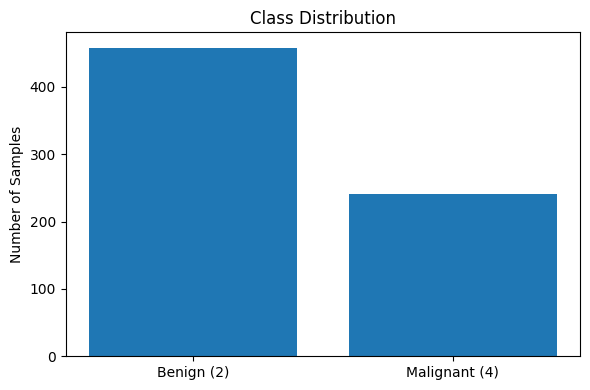

In [37]:
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Benign (2)", "Malignant (4)"], class_counts.values)
plt.title("Class Distribution")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

## 4. Missing Values and Data Cleaning

The `Bare Nuclei` column contains missing values represented by `?`.

The original coursework removed the affected rows. Because only a small number of samples are affected, the reconstructed version keeps the same simple approach instead of introducing a more advanced imputation method.

The sample identifier is also removed because it is not a predictive feature.

In [38]:
missing_mask = df.eq("?")

print("Missing values represented by '?':")
print(missing_mask.sum())

rows_with_missing = missing_mask.any(axis=1).sum()
print("\nRows containing missing values:", rows_with_missing)

Missing values represented by '?':
Sample code number              0
Clump Thickness                 0
Uniformity of Cell Size         0
Uniformity of Cell Shape        0
Marginal Adhesion               0
Single Epithelial Cell Size     0
Bare Nuclei                    16
Bland Chromatin                 0
Normal Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64

Rows containing missing values: 16


In [39]:
df_clean = df.replace("?", np.nan).copy()

df_clean["Bare Nuclei"] = pd.to_numeric(
    df_clean["Bare Nuclei"],
    errors="coerce",
)

df_clean = df_clean.dropna().reset_index(drop=True)

print("Shape after removing missing values:", df_clean.shape)

Shape after removing missing values: (683, 11)


In [40]:
df_clean = df_clean.drop(columns=["Sample code number"])

df_clean.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1.0,3,1,1,2
1,5,4,4,5,7,10.0,3,2,1,2
2,3,1,1,1,2,2.0,3,1,1,2
3,6,8,8,1,3,4.0,3,7,1,2
4,4,1,1,3,2,1.0,3,1,1,2


## 5. Class Encoding

For machine learning, the original labels are converted to:

- `0` → Benign
- `1` → Malignant

In [41]:
df_clean["Class"] = df_clean["Class"].map({2: 0, 4: 1})

print(df_clean["Class"].value_counts().sort_index())

Class
0    444
1    239
Name: count, dtype: int64


## 6. Exploratory Data Analysis

In [42]:
feature_columns = [col for col in df_clean.columns if col != "Class"]

df_clean[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Clump Thickness,683.0,4.442167,2.820761,1.0,2.0,4.0,6.0,10.0
Uniformity of Cell Size,683.0,3.150805,3.065145,1.0,1.0,1.0,5.0,10.0
Uniformity of Cell Shape,683.0,3.215227,2.988581,1.0,1.0,1.0,5.0,10.0
Marginal Adhesion,683.0,2.830161,2.864562,1.0,1.0,1.0,4.0,10.0
Single Epithelial Cell Size,683.0,3.234261,2.223085,1.0,2.0,2.0,4.0,10.0
Bare Nuclei,683.0,3.544656,3.643857,1.0,1.0,1.0,6.0,10.0
Bland Chromatin,683.0,3.445095,2.449697,1.0,2.0,3.0,5.0,10.0
Normal Nucleoli,683.0,2.869693,3.052666,1.0,1.0,1.0,4.0,10.0
Mitoses,683.0,1.603221,1.732674,1.0,1.0,1.0,1.0,10.0


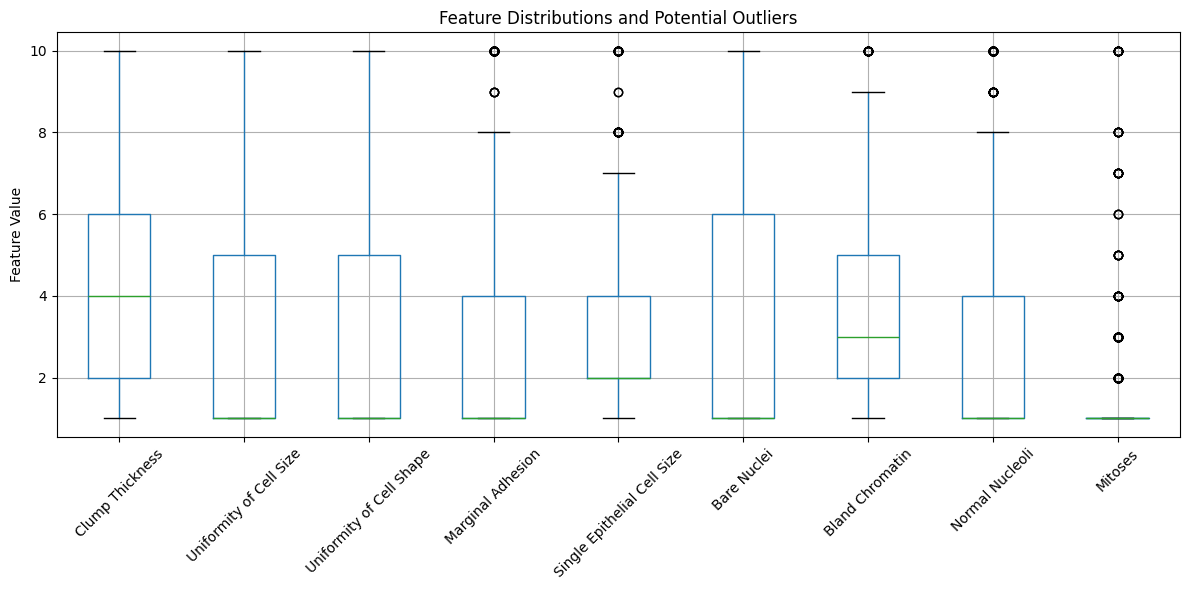

In [43]:
plt.figure(figsize=(12, 6))
df_clean[feature_columns].boxplot(rot=45)
plt.title("Feature Distributions and Potential Outliers")
plt.ylabel("Feature Value")
plt.tight_layout()
plt.show()

### Outlier handling

The boxplot shows that some variables contain values that may appear as statistical outliers.

However, these values are still valid measurements in the dataset. Therefore, this reconstructed version **does not automatically remove them**.

This avoids the bug in the original notebook where the filtering condition accidentally retained outliers instead of removing them.

## 7. Feature and Target Separation

In [44]:
X = df_clean[feature_columns].copy()
y = df_clean["Class"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (683, 9)
Target shape: (683,)


## 8. Supervised Learning

The original project compared three classifiers:

- Linear Discriminant Analysis
- Quadratic Discriminant Analysis
- Multinomial Naïve Bayes

The models are evaluated using three train/test ratios:

- 70/30
- 80/20
- 90/10

For reproducibility, a fixed `random_state` is used.

Stratification is also used so that the benign/malignant class ratio remains approximately consistent in the train and test sets.

In [45]:
split_configs = {
    "70/30": 0.30,
    "80/20": 0.20,
    "90/10": 0.10,
}

results = []
trained_models = {}

for split_name, test_size in split_configs.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    models = {
        "LDA": LinearDiscriminantAnalysis(),
        "QDA": QuadraticDiscriminantAnalysis(),
        "Naive Bayes": MultinomialNB(),
    }

    for model_name, model in models.items():
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)

        accuracy = accuracy_score(y_test, predictions)

        results.append({
            "Split": split_name,
            "Model": model_name,
            "Accuracy": accuracy,
        })

        trained_models[(split_name, model_name)] = {
            "model": model,
            "scaler": scaler,
            "X_test": X_test,
            "X_test_scaled": X_test_scaled,
            "y_test": y_test,
            "predictions": predictions,
        }

results_df = pd.DataFrame(results)
results_df

,Split,Model,Accuracy
0,70/30,LDA,0.936585
1,70/30,QDA,0.956098
2,70/30,Naive Bayes,0.902439
3,80/20,LDA,0.941606
4,80/20,QDA,0.963504
5,80/20,Naive Bayes,0.919708
6,90/10,LDA,0.956522
7,90/10,QDA,0.971014
8,90/10,Naive Bayes,0.927536


## 9. Supervised Model Comparison

In [46]:
results_pivot = results_df.pivot(
    index="Model",
    columns="Split",
    values="Accuracy",
)

(results_pivot * 100).round(2)

Split,70/30,80/20,90/10
Model,,,
LDA,93.66,94.16,95.65
Naive Bayes,90.24,91.97,92.75
QDA,95.61,96.35,97.10


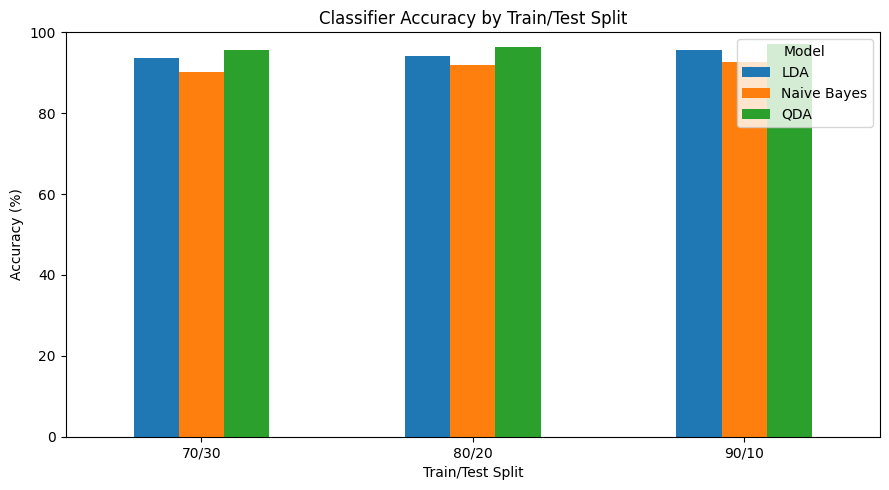

In [47]:
ax = (results_pivot * 100).T.plot(
    kind="bar",
    figsize=(9, 5),
)

plt.title("Classifier Accuracy by Train/Test Split")
plt.ylabel("Accuracy (%)")
plt.xlabel("Train/Test Split")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## 10. Detailed Classification Results

The 80/20 split is used as a representative configuration for detailed reports and confusion matrices.

In [48]:
selected_split = "80/20"

for model_name in ["LDA", "QDA", "Naive Bayes"]:
    result = trained_models[(selected_split, model_name)]

    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(
        classification_report(
            result["y_test"],
            result["predictions"],
            target_names=["Benign", "Malignant"],
            digits=4,
        )
    )

LDA
              precision    recall  f1-score   support

      Benign     0.9551    0.9551    0.9551        89
   Malignant     0.9167    0.9167    0.9167        48

    accuracy                         0.9416       137
   macro avg     0.9359    0.9359    0.9359       137
weighted avg     0.9416    0.9416    0.9416       137

QDA
              precision    recall  f1-score   support

      Benign     0.9884    0.9551    0.9714        89
   Malignant     0.9216    0.9792    0.9495        48

    accuracy                         0.9635       137
   macro avg     0.9550    0.9671    0.9605       137
weighted avg     0.9650    0.9635    0.9637       137

Naive Bayes
              precision    recall  f1-score   support

      Benign     0.9239    0.9551    0.9392        89
   Malignant     0.9111    0.8542    0.8817        48

    accuracy                         0.9197       137
   macro avg     0.9175    0.9046    0.9105       137
weighted avg     0.9194    0.9197    0.9191       137


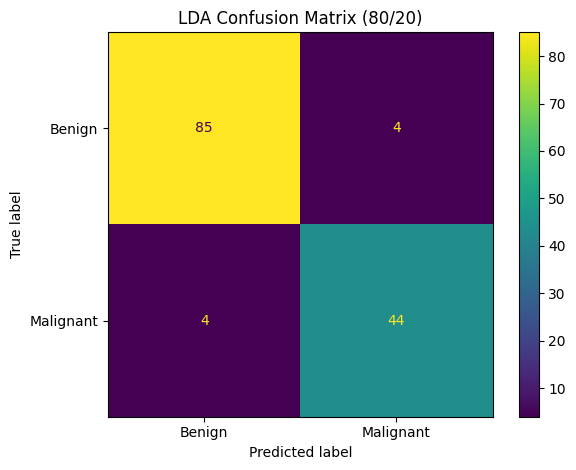

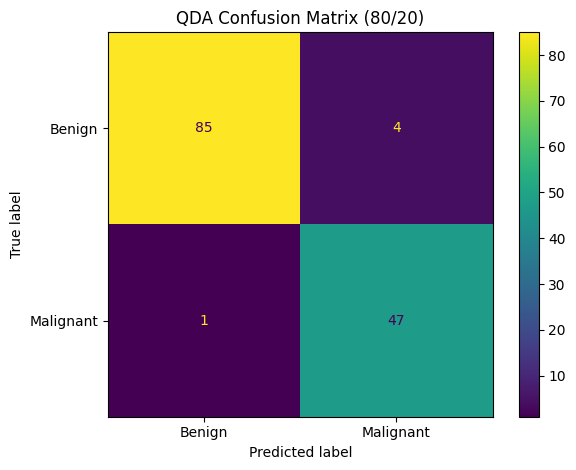

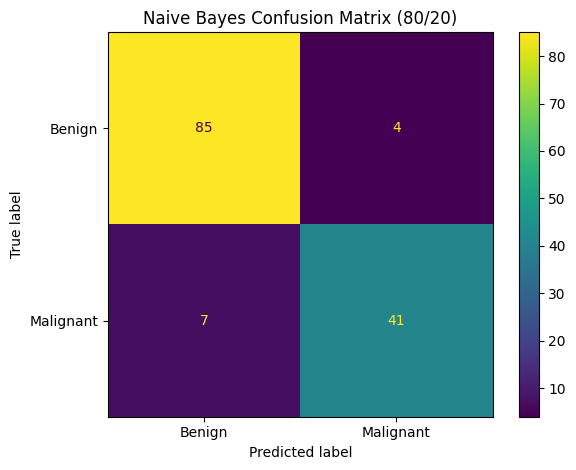

In [49]:
for model_name in ["LDA", "QDA", "Naive Bayes"]:
    result = trained_models[(selected_split, model_name)]

    ConfusionMatrixDisplay.from_predictions(
        result["y_test"],
        result["predictions"],
        display_labels=["Benign", "Malignant"],
    )

    plt.title(f"{model_name} Confusion Matrix ({selected_split})")
    plt.tight_layout()
    plt.show()

## 11. Unsupervised Learning — K-Means

K-Means clustering is used to investigate whether the samples naturally form two groups that resemble the benign and malignant classes.

For clustering, the complete feature matrix is scaled using Min-Max normalization.

In [50]:
cluster_scaler = MinMaxScaler()
X_scaled = cluster_scaler.fit_transform(X)

## 12. Elbow Method

The Elbow Method is used to inspect the within-cluster sum of squares (inertia) for different numbers of clusters.

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known

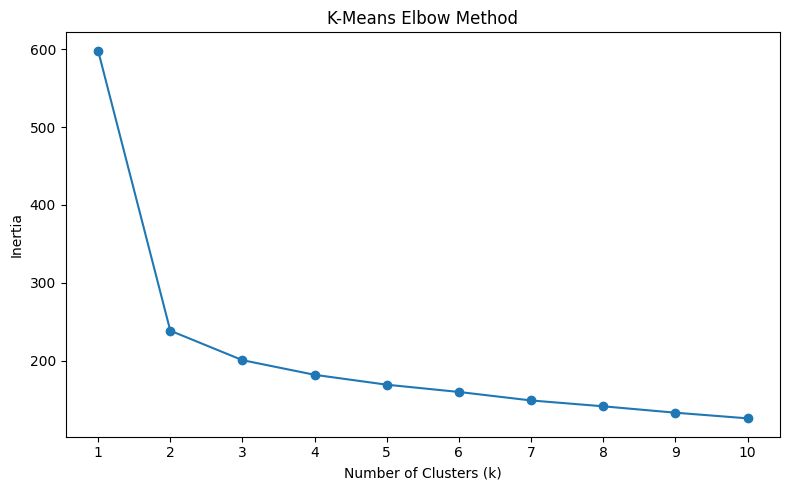

In [51]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
    )

    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

## 13. Silhouette Analysis

Silhouette scores are calculated for multiple cluster counts.

A larger silhouette score generally indicates better separation between clusters.

In [52]:
silhouette_results = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
    )

    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)

    silhouette_results.append({
        "k": k,
        "Silhouette Score": score,
    })

silhouette_df = pd.DataFrame(silhouette_results)
silhouette_df

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known

,k,Silhouette Score
0,2,0.596798
1,3,0.525677
2,4,0.535941
3,5,0.260256
4,6,0.249684


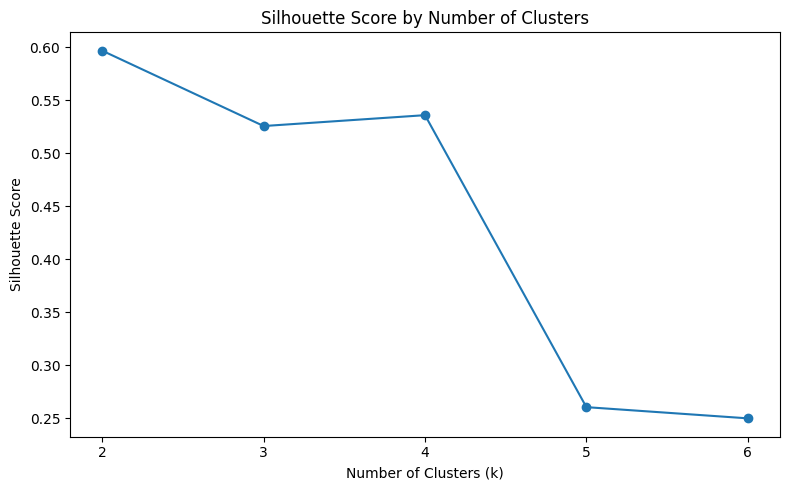

In [53]:
plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["k"],
    silhouette_df["Silhouette Score"],
    marker="o",
)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(silhouette_df["k"])
plt.tight_layout()
plt.show()

## 14. K-Means with Two Clusters

Because the dataset represents two known diagnostic classes, K-Means is also evaluated with `k = 2`.

Cluster IDs are arbitrary. Therefore, the cluster labels must first be mapped to the true diagnostic classes before calculating classification-style metrics.

In [54]:
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=RANDOM_STATE,
    n_init=10,
)

cluster_labels = kmeans_2.fit_predict(X_scaled)

cluster_comparison = pd.crosstab(
    pd.Series(cluster_labels, name="Cluster"),
    pd.Series(y.values, name="True Class"),
)

cluster_comparison

c:\Users\arion\anaconda3\envs\cv\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


True Class,0,1
Cluster,,
0,9,221
1,435,18


In [55]:
cluster_to_class = {}

for cluster_id in np.unique(cluster_labels):
    mask = cluster_labels == cluster_id
    majority_class = y.iloc[np.where(mask)[0]].mode().iloc[0]
    cluster_to_class[cluster_id] = majority_class

mapped_predictions = np.array(
    [cluster_to_class[label] for label in cluster_labels]
)

kmeans_accuracy = accuracy_score(y, mapped_predictions)

print("Cluster-to-class mapping:", cluster_to_class)
print(f"K-Means mapped accuracy: {kmeans_accuracy:.4f}")

Cluster-to-class mapping: {0: 1, 1: 0}
K-Means mapped accuracy: 0.9605


In [56]:
print(
    classification_report(
        y,
        mapped_predictions,
        target_names=["Benign", "Malignant"],
        digits=4,
    )
)

              precision    recall  f1-score   support

      Benign     0.9603    0.9797    0.9699       444
   Malignant     0.9609    0.9247    0.9424       239

    accuracy                         0.9605       683
   macro avg     0.9606    0.9522    0.9562       683
weighted avg     0.9605    0.9605    0.9603       683



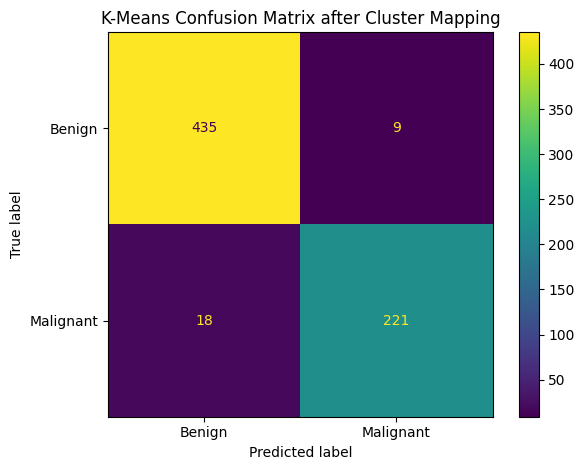

In [57]:
ConfusionMatrixDisplay.from_predictions(
    y,
    mapped_predictions,
    display_labels=["Benign", "Malignant"],
)

plt.title("K-Means Confusion Matrix after Cluster Mapping")
plt.tight_layout()
plt.show()

## 15. Hierarchical Clustering

Hierarchical clustering is performed using **Ward linkage**.

The dendrogram visualizes how samples are progressively merged into larger clusters.

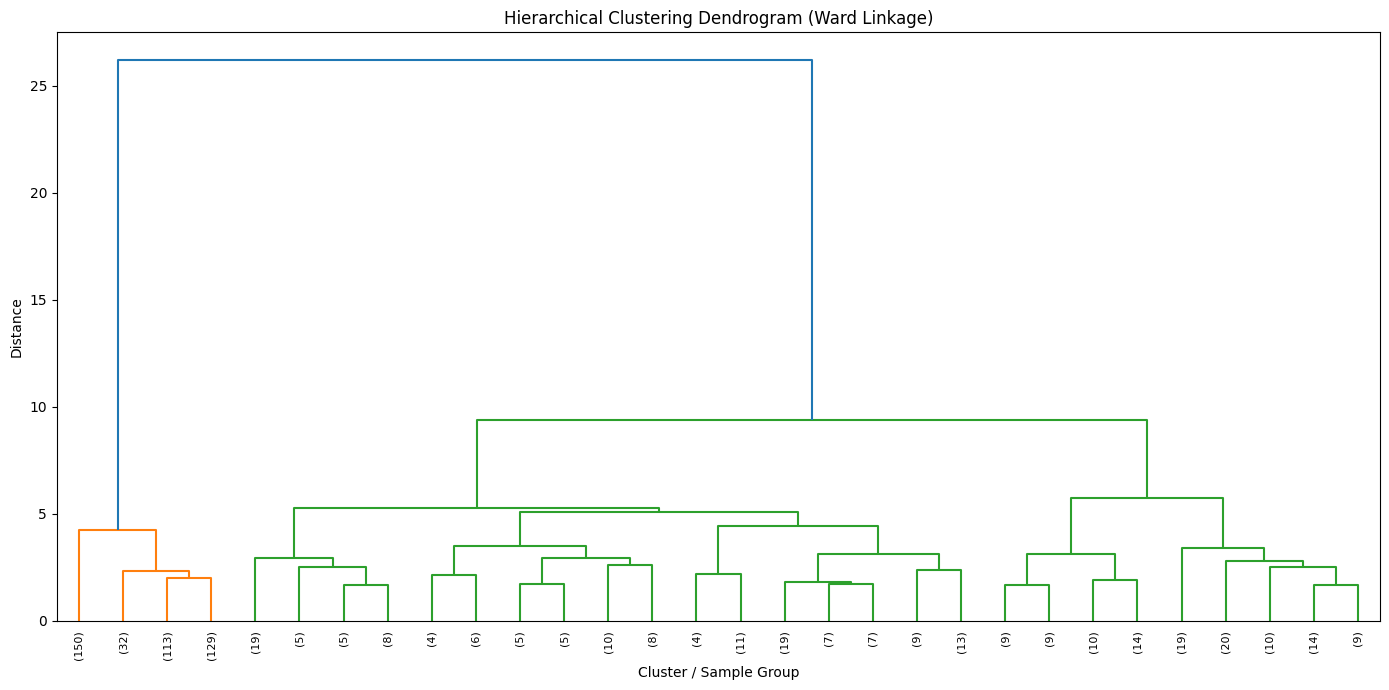

In [58]:
linked = linkage(
    X_scaled,
    method="ward",
)

plt.figure(figsize=(14, 7))
dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
)

plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster / Sample Group")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

## 16. Summary of Results

The supervised models can now be compared using the table below.

In [59]:
summary_table = results_df.copy()
summary_table["Accuracy (%)"] = (
    summary_table["Accuracy"] * 100
).round(2)

summary_table = summary_table.drop(columns=["Accuracy"])
summary_table

,Split,Model,Accuracy (%)
0,70/30,LDA,93.66
1,70/30,QDA,95.61
2,70/30,Naive Bayes,90.24
3,80/20,LDA,94.16
4,80/20,QDA,96.35
5,80/20,Naive Bayes,91.97
6,90/10,LDA,95.65
7,90/10,QDA,97.10
8,90/10,Naive Bayes,92.75


In [60]:
best_result = results_df.loc[results_df["Accuracy"].idxmax()]

print("Best supervised result:")
print(
    f"{best_result['Model']} - "
    f"{best_result['Split']} split - "
    f"{best_result['Accuracy'] * 100:.2f}% accuracy"
)

print(f"\nK-Means mapped accuracy: {kmeans_accuracy * 100:.2f}%")

Best supervised result:
QDA - 90/10 split - 97.10% accuracy

K-Means mapped accuracy: 96.05%


## 17. Conclusions

This reconstructed project demonstrates the use of classical Pattern Recognition and Machine Learning techniques on the Wisconsin Breast Cancer dataset.

The main supervised approaches are:

- Linear Discriminant Analysis
- Quadratic Discriminant Analysis
- Multinomial Naïve Bayes

The project also explores unsupervised learning through:

- K-Means clustering
- Elbow Method
- Silhouette Analysis
- Hierarchical Clustering

Compared with the original university notebook, the reconstructed implementation improves:

- correct dataset loading,
- reproducibility,
- class stratification,
- feature scaling without supervised data leakage,
- target encoding,
- clustering evaluation,
- documentation,
- and code clarity.

The purpose of these changes is not to turn the coursework into a more advanced modern ML project, but to preserve the original academic scope while making the implementation correct, understandable, and suitable for a GitHub portfolio.

## 18. Notes and Limitations

This remains a university-level Pattern Recognition project.

Some intentionally advanced techniques are not included, such as:

- deep learning,
- extensive hyperparameter optimization,
- production ML pipelines,
- deployment,
- or advanced feature engineering.

These techniques would change the scope of the original coursework and are therefore outside the purpose of this reconstruction.